# Mini-Project 2: Solar Micro-Grid Dispatch Planner

This notebook models the daily demands with `3x + 2y = D1` and `4x + y = D2`, where `x` is solar generation and `y` is battery energy (kWh). The generated 30-day data are synthetic and reproducible, with a weekly pattern and noise. The UGX 150/kWh solar and UGX 450/kWh battery rates are illustrative assumptions, not a tariff quotation.

In [1]:
from pathlib import Path
import timeit

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.microgrid import (
    HybridMicroGrid,
    MicroGrid,
    daily_energy_cost,
    generate_daily_demands,
    load_demand_csv,
    read_nonnegative_float,
    sensitivity_analysis,
    usage_statistics,
)

## Matrix well-posedness

A nonzero determinant means this square system has a unique exact solution. The condition number indicates sensitivity of that solution to small perturbations in the inputs: a larger value means greater potential amplification of input error. Neither value alone determines whether the resulting source allocations are physically nonnegative.

In [2]:
grid = MicroGrid()
print("Coefficient matrix:\n", grid.coefficient_matrix)
print("Determinant:", grid.well_posedness["determinant"])
print("Condition number:", grid.well_posedness["condition_number"])
print("Well-posed:", grid.well_posedness["is_well_posed"])

Coefficient matrix:
 [[3. 2.]
 [4. 1.]]
Determinant: -4.999999999999999
Condition number: 5.82842712474619
Well-posed: True


## Generate and load the 30-day CSV

The generator uses NumPy's seeded random generator. Weekday factors give a weekly demand pattern; independent noise adds modest day-to-day variation. To use a different demand file, place columns named `day`, `d1`, and `d2` in a CSV and pass its path to `load_demand_csv`.

In [3]:
data_directory = Path("data")
data_directory.mkdir(exist_ok=True)
csv_path = data_directory / "daily_demands.csv"
generated_demands = generate_daily_demands(days=30, seed=2026)
generated_demands.to_csv(csv_path, index=False)
demands = load_demand_csv(csv_path)
print(f"Loaded {len(demands)} synthetic demand days from {csv_path}")
display(demands.head())

Loaded 30 synthetic demand days from data\daily_demands.csv


,day,d1,d2
0,1,156.436820,183.884196
1,2,170.538490,191.719478
2,3,149.327259,165.829917
3,4,172.651773,198.063206
4,5,167.137869,196.688547


## Interactive input option

`read_nonnegative_float` rejects empty, non-numeric, non-finite and negative inputs and prompts again. The example below simulates a bad entry followed by a valid one so that **Restart & Run All** does not block waiting for keyboard input. For interactive use, call the commented example with the default `input` function.

In [4]:
input_values = iter(["not a number", "110"])
validation_messages = []
example_d1 = read_nonnegative_float(
    "Daytime demand D1 (kWh): ",
    input_fn=lambda _prompt: next(input_values),
    output_fn=validation_messages.append,
)
print("Accepted D1:", example_d1, "| rejected-entry messages:", validation_messages)

# For an interactive solve, uncomment these lines in a live notebook:
# d1 = read_nonnegative_float("Daytime demand D1 (kWh): ")
# d2 = read_nonnegative_float("Critical-equipment demand D2 (kWh): ")
# print(grid.solve_day(d1, d2))

Accepted D1: 110.0 | rejected-entry messages: ['Enter a numeric value.']


## Loop and vectorized solves

The vectorized path passes a `2 × 30` right-hand-side matrix to `scipy.linalg.solve`. Both approaches apply the same nonnegative-feasibility check and NNLS fallback, so their daily allocations should agree.

In [5]:
demand_matrix = demands[["d1", "d2"]].to_numpy(dtype=float)
loop_seconds = timeit.timeit(lambda: grid.solve_days_loop(demand_matrix), number=100)
vectorized_seconds = timeit.timeit(lambda: grid.solve_days_vectorized(demand_matrix), number=100)
loop_solutions = grid.solve_days_loop(demand_matrix)
solutions = grid.solve_days_vectorized(demand_matrix)
assert all(np.allclose(a.usage, b.usage) for a, b in zip(loop_solutions, solutions))
print(f"Loop total for 100 runs: {loop_seconds:.4f} s")
print(f"Vectorized total for 100 runs: {vectorized_seconds:.4f} s")
print(f"Infeasible exact solutions handled by NNLS: {sum(not s.feasible for s in solutions)}")
print("NNLS substitutes a nonnegative least-squares allocation and reports its residual; it cannot always satisfy both equalities exactly.")

results = demands.copy()
results["solar_kwh"] = [solution.solar for solution in solutions]
results["battery_kwh"] = [solution.battery for solution in solutions]
results["feasible_exactly"] = [solution.feasible for solution in solutions]
results["method"] = [solution.method for solution in solutions]
results["residual_norm"] = [solution.residual_norm for solution in solutions]
display(results.head())

Loop total for 100 runs: 0.3720 s
Vectorized total for 100 runs: 0.1173 s
Infeasible exact solutions handled by NNLS: 0
NNLS substitutes a nonnegative least-squares allocation and reports its residual; it cannot always satisfy both equalities exactly.


,day,d1,d2,solar_kwh,battery_kwh,feasible_exactly,method,residual_norm
0,1,156.436820,183.884196,42.266314,14.818939,True,direct,0.000000e+00
1,2,170.538490,191.719478,42.580093,21.399105,True,direct,0.000000e+00
2,3,149.327259,165.829917,36.466515,19.963857,True,direct,0.000000e+00
3,4,172.651773,198.063206,44.694928,19.283495,True,direct,0.000000e+00
4,5,167.137869,196.688547,45.247845,15.697167,True,direct,2.842171e-14


## Usage statistics and illustrative cost model

Variance and standard deviation below use the sample definitions from Python's `statistics` module. Compare source standard deviations to identify which source varies more across these days. Monthly cost here is the sum of the 30 daily energy costs, not a projection to a 31-day month.

In [6]:
statistics_table = pd.DataFrame(usage_statistics(solutions)).T
display(statistics_table.round(2))
most_volatile = statistics_table["standard_deviation"].idxmax()
print(f"More volatile source by sample standard deviation: {most_volatile}")

results["daily_cost_ugx"] = daily_energy_cost(results["solar_kwh"].to_numpy(), results["battery_kwh"].to_numpy())
print(f"First-day energy cost: UGX {results.loc[0, 'daily_cost_ugx']:,.0f}")
print(f"30-day total energy cost: UGX {results['daily_cost_ugx'].sum():,.0f}")
print("Rates used: solar UGX 150/kWh; battery UGX 450/kWh (illustrative).")

,mean,variance,standard_deviation
solar,41.40,11.31,3.36
battery,18.46,6.02,2.45


More volatile source by sample standard deviation: solar
First-day energy cost: UGX 13,008
30-day total energy cost: UGX 435,510
Rates used: solar UGX 150/kWh; battery UGX 450/kWh (illustrative).


## Daily dispatch and cost plot

The stacked bars show the energy sources. A secondary vertical axis overlays the daily illustrative cost.

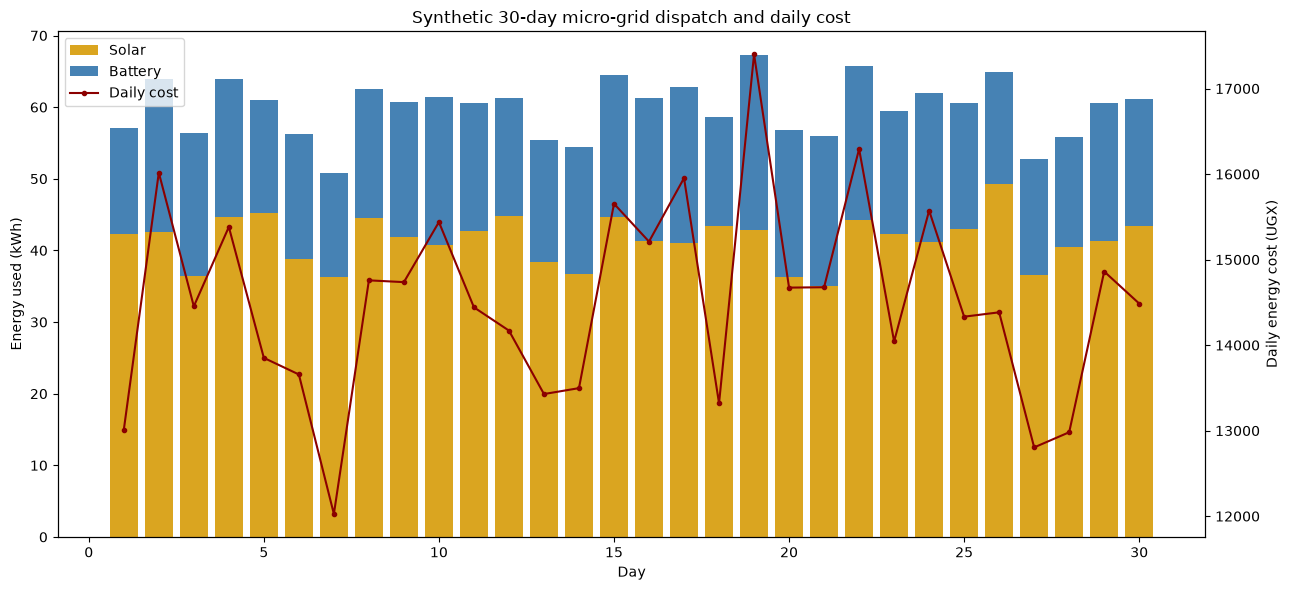

In [7]:
fig, usage_axis = plt.subplots(figsize=(13, 6))
usage_axis.bar(results["day"], results["solar_kwh"], label="Solar", color="goldenrod")
usage_axis.bar(results["day"], results["battery_kwh"], bottom=results["solar_kwh"], label="Battery", color="steelblue")
usage_axis.set_xlabel("Day")
usage_axis.set_ylabel("Energy used (kWh)")
usage_axis.set_title("Synthetic 30-day micro-grid dispatch and daily cost")
cost_axis = usage_axis.twinx()
cost_axis.plot(results["day"], results["daily_cost_ugx"], color="darkred", marker="o", markersize=3, label="Daily cost")
cost_axis.set_ylabel("Daily energy cost (UGX)")
usage_handles, usage_labels = usage_axis.get_legend_handles_labels()
cost_handles, cost_labels = cost_axis.get_legend_handles_labels()
usage_axis.legend(usage_handles + cost_handles, usage_labels + cost_labels, loc="upper left")
fig.tight_layout()
plt.show()

## Extension: diesel hybrid and sensitivity analysis

The third equation `x + y + z = D3` represents a chosen total-source constraint. The three equations have independent rows for the example matrix. If the new equation were a linear combination of the first two, the determinant would be zero and the system would not have a unique solution; depending on demand consistency there could be no solution or infinitely many, and a condition number would be very large/infinite. Sensitivity perturbs each of `D1` and `D2` independently by ±5% for 1,000 seeded draws.

In [8]:
hybrid_grid = HybridMicroGrid()
hybrid_solution = hybrid_grid.solve_day(100, 120, 60)
print("Hybrid determinant and condition number:", hybrid_grid.well_posedness)
print("Solar, battery, diesel allocation (kWh):", hybrid_solution.usage)

dependent_grid = HybridMicroGrid(np.array([[3, 2, 1], [4, 1, 2], [7, 3, 3]], dtype=float))
print("Example linearly dependent system is well-posed:", dependent_grid.well_posedness["is_well_posed"])

sensitivity_table = sensitivity_analysis(grid, float(demands.loc[0, "d1"]), float(demands.loc[0, "d2"]), draws=1_000, seed=2026)
display(sensitivity_table.round(3))

Hybrid determinant and condition number: {'determinant': -4.0, 'condition_number': 10.058932143505537, 'is_well_posed': True}
Solar, battery, diesel allocation (kWh): [10. 20. 30.]
Example linearly dependent system is well-posed: False


,source,mean_absolute_change,95th_percentile_absolute_change,maximum_absolute_change
0,solar,1.942,4.061,5.029
1,battery,3.991,9.076,11.381


## Findings & Limitations

The coefficient matrix has determinant −5 and condition number about 5.83, so the two demand equations have a unique solution and are not especially ill-conditioned relative to a nearly singular system. The generated 30-day series follows a weekly pattern with seeded random variation, making the loop and vectorized calculations reproducible. Both solving approaches should return the same allocations; vectorization reduces Python-level repetition, although for only 30 two-variable systems the timing difference is small and machine-dependent. Any negative exact allocation is physically unusable, so the implementation flags that day and substitutes a nonnegative least-squares solution. That fallback may leave a residual because it prioritizes nonnegative sources rather than satisfying incompatible equalities exactly.

The reported sample variances and standard deviations summarize only this synthetic month; they do not establish real solar or battery reliability. Costs use the assignment's illustrative rates, exclude fixed charges, storage losses, degradation, capital costs and time-of-use pricing, and the monthly total covers exactly 30 generated days. The hybrid extension's third constraint is an assumed model choice; real dispatch requires measured source limits and a justified third relationship. Monte Carlo perturbations quantify local changes under independent ±5% demand variation only. They do not capture correlated demand errors, uncertainty in the coefficients, equipment constraints or seasonal conditions. The dataset, cost rates and sensitivity assumptions must be replaced with verified site data before operational or investment decisions.

## References

- Course assignment prompt for the two demand equations, illustrative cost rates and project requirements.
- NumPy documentation: [`numpy.linalg.det`](https://numpy.org/doc/stable/reference/generated/numpy.linalg.det.html), [`numpy.linalg.cond`](https://numpy.org/doc/stable/reference/generated/numpy.linalg.cond.html), and [`numpy.random.default_rng`](https://numpy.org/doc/stable/reference/random/generator.html).
- SciPy documentation: [`scipy.linalg.solve`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.linalg.solve.html) and [`scipy.optimize.nnls`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.nnls.html).
- Python documentation: [`timeit`](https://docs.python.org/3/library/timeit.html) and [`statistics`](https://docs.python.org/3/library/statistics.html).
- Matplotlib documentation: [`Axes.bar`](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.bar.html) and [`Axes.twinx`](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.twinx.html).
- The generated CSV is synthetic and reproducible from the code in this notebook; it is not an external measurement.